# NB68 log — temporary plots (not a numbered experiment)

Reads the raw run log `resources/68_comparison.jsonl` (4,736 runs: 2 methods × 2 sources × λ∈{0, 0.4} × 74 configs × 8 prompts)
and plots cosine gain vs fluency cost. Only the headline plot is written, to `resources/68_log_gain_vs_ppl.png`.

- **Cosine**: `signed_mean_delta` (steered − baseline, attraction minus repulsion for counterfactuals). *Own view* = the reference family
  that matches the run (source × frame for FRH, source × subspace for subspace); *all views* are shown separately.
- **Fluency**: continuation-only ΔPPL (steered − baseline). Heavy-tailed, so medians + IQR.
- Invalid rows (empty continuation / non-finite PPL) are dropped per metric and counted in the last section.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
sns.set_context("paper", font_scale=1.3)
METHOD_COLOR = {"frh_blend": "#2a78d6", "subspace": "#eb6834"}
SOURCE_STYLE = {"wordnet": "-", "custom": "--"}
SOURCE_MARKER = {"wordnet": "o", "custom": "s"}
LOG = "resources/68_comparison.jsonl"
EXCLUDE_PROMPTS = {"p07"}  # unsteered baseline is empty -> no run on it is scorable


In [2]:
all_raw = [json.loads(l) for l in open(LOG)]
raw = [r for r in all_raw if r["prompt"]["id"] not in EXCLUDE_PROMPTS]
base, views = [], []
for r in raw:
    f = r["metrics"]["fluency"]
    row = dict(
        run_id=r["run_id"], source=r["source"], method=r["method"], lam=r["lambda"],
        config=r["config"]["id"], kind=r["config"]["kind"], units=r["config"]["unit_count"],
        prompt=r["prompt"]["id"], tokens=r["metrics"]["continuation_tokens"],
        ppl_valid=f["valid"], ppl_invalid=f["invalid_reason"],
        steered_ppl=f["steered_ppl"], baseline_ppl=f["baseline_ppl"], delta_ppl=f["delta_ppl"],
        continuation=r["continuation"],
    )
    base.append(row)
    own = f'{r["source"]}_{"frame" if r["method"] == "frh_blend" else "subspace"}'
    for v, m in r["metrics"]["cosine"].items():
        s = m.get("summary") or {}
        views.append(dict(
            run_id=r["run_id"], view=v, own=(v == own), cos_valid=m["valid"],
            signed=s.get("signed_mean_delta"), attract=s.get("attraction_mean_delta"),
            repel=s.get("repulsion_mean_reduction"), all_improved=s.get("all_requested_improved"),
        ))
runs = pd.DataFrame(base)
cos = pd.DataFrame(views).merge(runs, on="run_id")
own = cos[cos.own]
print(runs.shape, cos.shape, "invalid after exclusion:", (~runs.ppl_valid).sum(), (~cos.cos_valid).sum())
runs.groupby(["method", "source", "lam"]).size().unstack()

(4144, 15) (16576, 22) invalid after exclusion: 0 0


lam                0.0  0.4
method    source           
frh_blend custom   518  518
          wordnet  518  518
subspace  custom   518  518
          wordnet  518  518

## 1. Headline: own-view cosine gain vs ΔPPL, per method × source × λ

,method,source,lam,cos,cos_se,ppl_med,ppl_q1,ppl_q3,win,n
0,frh_blend,custom,0.0,0.0097,0.0004,53.9830,34.4823,86.9561,0.5405,518
1,frh_blend,custom,0.4,0.0074,0.0004,14.9897,6.7008,25.3442,0.5309,518
2,frh_blend,wordnet,0.0,0.0043,0.0004,65.2482,41.3495,106.5901,0.4112,518
3,frh_blend,wordnet,0.4,0.0017,0.0003,11.9298,4.6641,21.6813,0.3417,518
4,subspace,custom,0.0,0.0184,0.0008,93.2193,50.5817,217.0066,0.6409,518
5,subspace,custom,0.4,0.0163,0.0007,37.6063,17.2760,136.9367,0.6332,518
6,subspace,wordnet,0.0,0.0104,0.0005,86.8445,46.7112,163.0289,0.5869,518
7,subspace,wordnet,0.4,0.0085,0.0005,26.1548,12.0835,60.8750,0.5386,518


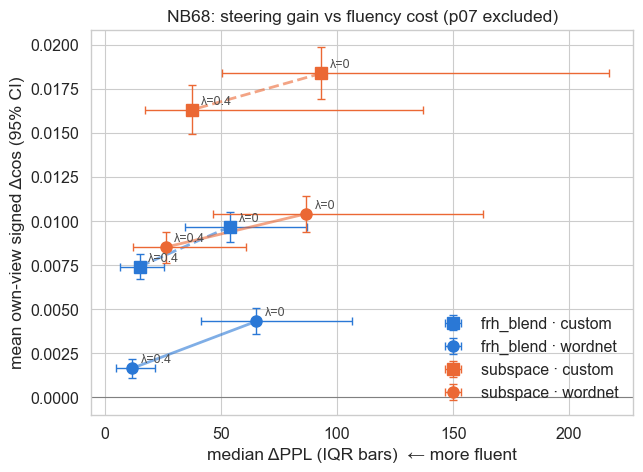

In [3]:
v = own[own.cos_valid & own.ppl_valid]
agg = v.groupby(["method", "source", "lam"]).agg(
    cos=("signed", "mean"), cos_se=("signed", "sem"),
    ppl_med=("delta_ppl", "median"), ppl_q1=("delta_ppl", lambda x: x.quantile(.25)),
    ppl_q3=("delta_ppl", lambda x: x.quantile(.75)), win=("all_improved", "mean"), n=("signed", "size"),
).reset_index()
display(agg.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for (m, s), g in agg.groupby(["method", "source"]):
    g = g.sort_values("lam")
    ax.plot(g.ppl_med, g.cos, SOURCE_STYLE[s], color=METHOD_COLOR[m], lw=2, alpha=.6)
    ax.errorbar(g.ppl_med, g.cos, yerr=1.96 * g.cos_se,
                xerr=[g.ppl_med - g.ppl_q1, g.ppl_q3 - g.ppl_med],
                fmt=SOURCE_MARKER[s], color=METHOD_COLOR[m], ms=8, capsize=3, lw=1, label=f"{m} · {s}")
    for _, r in g.iterrows():
        ax.annotate(f"λ={r.lam:g}", (r.ppl_med, r.cos), textcoords="offset points", xytext=(6, 4), fontsize=9, color="0.3")
ax.axhline(0, color="0.5", lw=.8)
ax.set_xlabel("median ΔPPL (IQR bars)  ← more fluent")
ax.set_ylabel("mean own-view signed Δcos (95% CI)")
ax.set_title("NB68: steering gain vs fluency cost (p07 excluded)")
ax.legend(frameon=False)
fig.savefig("resources/68_log_gain_vs_ppl.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Scaling with number of steering units (own view)

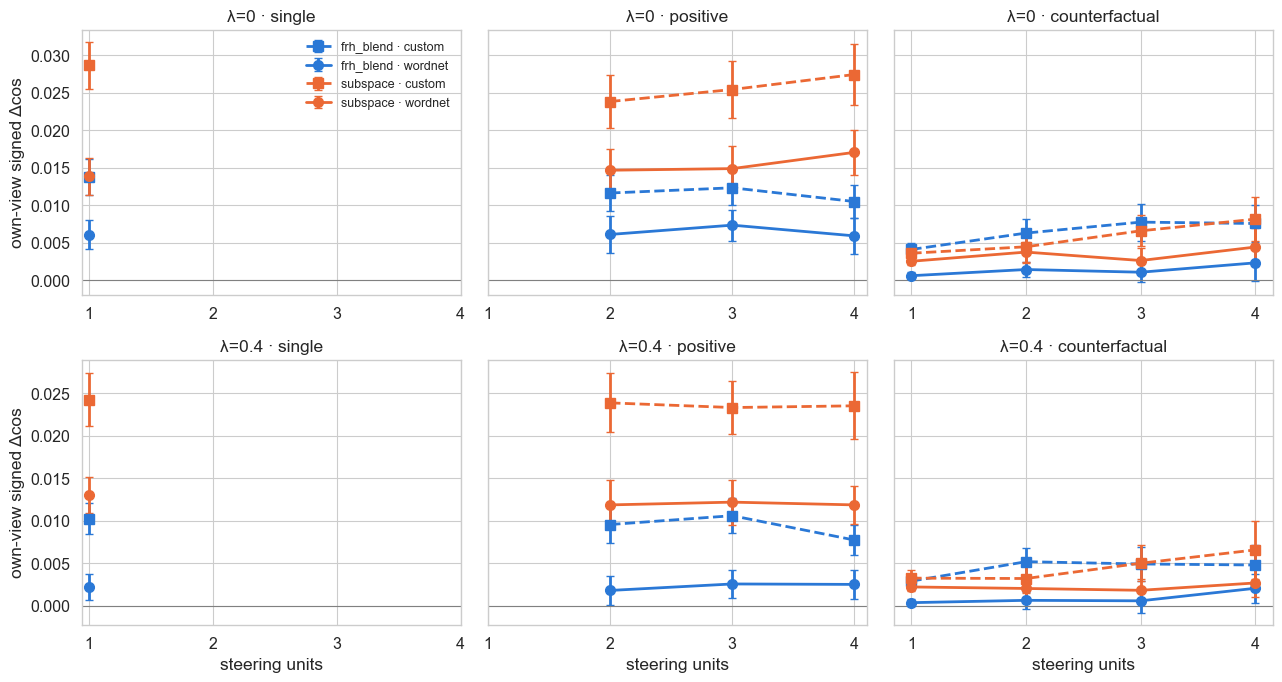

In [4]:
g = own[own.cos_valid].groupby(["lam", "kind", "units", "method", "source"]).signed.agg(["mean", "sem"]).reset_index()
lams, kinds = sorted(g.lam.unique()), ["single", "positive", "counterfactual"]
fig, axes = plt.subplots(len(lams), len(kinds), figsize=(13, 7), sharey="row", squeeze=False)
for i, lam in enumerate(lams):
    for j, k in enumerate(kinds):
        ax = axes[i, j]
        for (m, s), d in g[(g.lam == lam) & (g.kind == k)].groupby(["method", "source"]):
            ax.errorbar(d.units, d["mean"], yerr=1.96 * d["sem"], ls=SOURCE_STYLE[s], marker=SOURCE_MARKER[s],
                        color=METHOD_COLOR[m], lw=2, ms=7, capsize=3, label=f"{m} · {s}")
        ax.axhline(0, color="0.5", lw=.8)
        ax.set_title(f"λ={lam:g} · {k}")
        ax.set_xticks([1, 2, 3, 4])
        if i == len(lams) - 1: ax.set_xlabel("steering units")
        if j == 0: ax.set_ylabel("own-view signed Δcos")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

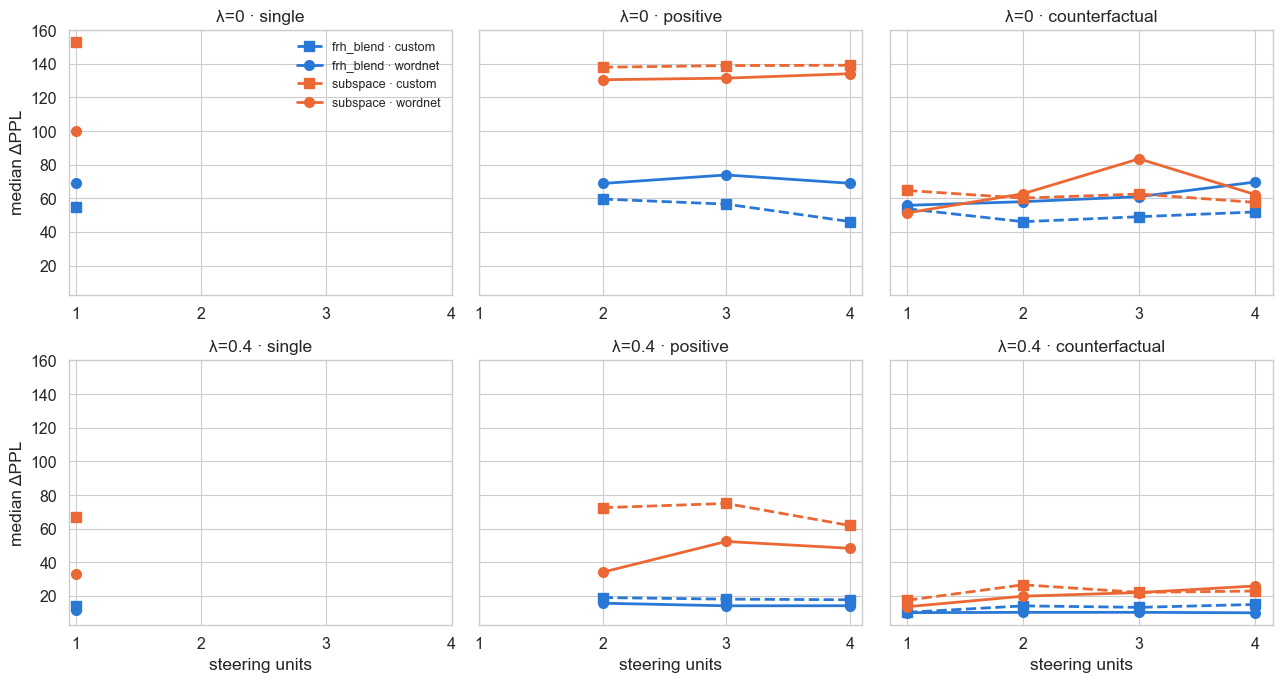

In [5]:
g = runs[runs.ppl_valid].groupby(["lam", "kind", "units", "method", "source"]).delta_ppl.median().reset_index()
fig, axes = plt.subplots(len(lams), len(kinds), figsize=(13, 7), sharey=True, squeeze=False)
for i, lam in enumerate(lams):
    for j, k in enumerate(kinds):
        ax = axes[i, j]
        for (m, s), d in g[(g.lam == lam) & (g.kind == k)].groupby(["method", "source"]):
            ax.plot(d.units, d.delta_ppl, ls=SOURCE_STYLE[s], marker=SOURCE_MARKER[s], color=METHOD_COLOR[m], lw=2, ms=7, label=f"{m} · {s}")
        ax.set_title(f"λ={lam:g} · {k}"); ax.set_xticks([1, 2, 3, 4])
        if i == len(lams) - 1: ax.set_xlabel("steering units")
        if j == 0: ax.set_ylabel("median ΔPPL")
axes[0, 0].legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

## 3. Cross-view robustness — does each method win on every reference family?

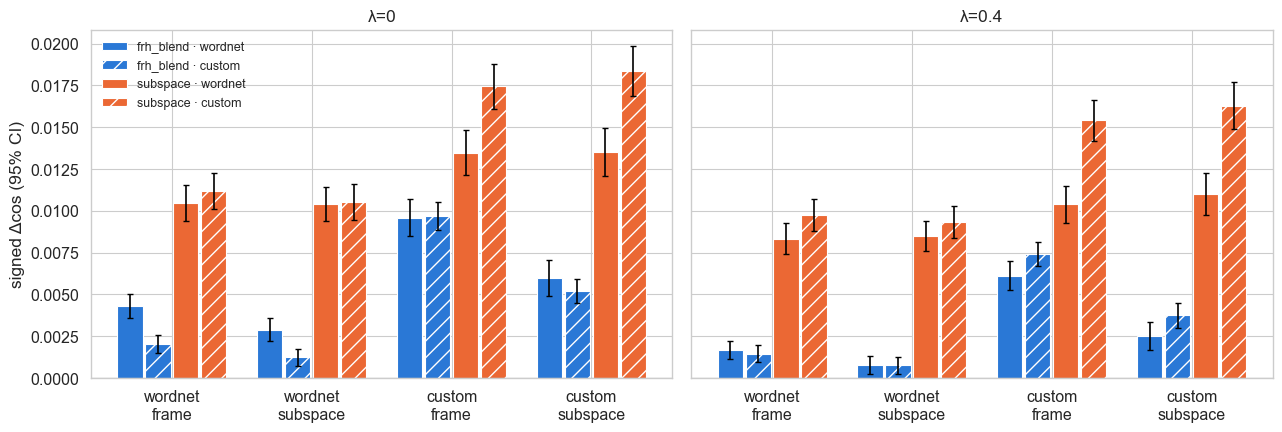

In [6]:
g = cos[cos.cos_valid].groupby(["lam", "view", "method", "source"]).signed.agg(["mean", "sem"]).reset_index()
fig, axes = plt.subplots(1, len(lams), figsize=(13, 4.5), sharey=True)
order = ["wordnet_frame", "wordnet_subspace", "custom_frame", "custom_subspace"]
combos = [("frh_blend", "wordnet"), ("frh_blend", "custom"), ("subspace", "wordnet"), ("subspace", "custom")]
w = .2
for ax, lam in zip(axes, lams):
    for c, (m, s) in enumerate(combos):
        d = g[(g.lam == lam) & (g.method == m) & (g.source == s)].set_index("view").reindex(order)
        x = np.arange(len(order)) + (c - 1.5) * w
        ax.bar(x, d["mean"], w * .9, yerr=1.96 * d["sem"], color=METHOD_COLOR[m],
               hatch=None if s == "wordnet" else "//", edgecolor="white", capsize=2, label=f"{m} · {s}")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace("_", "\n") for o in order])
    ax.axhline(0, color="0.5", lw=.8); ax.set_title(f"λ={lam:g}")
axes[0].set_ylabel("signed Δcos (95% CI)"); axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); plt.show()

## 4. Paired FRH − subspace (same source, λ, config, prompt)

,source,lam,view,mean,lo,hi,frac_frh_better,n
0,custom,0.0,custom_frame,-0.0078,-0.0091,-0.0066,0.3475,518
1,custom,0.0,custom_subspace,-0.0132,-0.0146,-0.0118,0.2085,518
2,custom,0.0,wordnet_frame,-0.0091,-0.0102,-0.0081,0.2471,518
3,custom,0.0,wordnet_subspace,-0.0093,-0.0103,-0.0082,0.2664,518
4,custom,0.4,custom_frame,-0.0080,-0.0092,-0.0069,0.3436,518
5,custom,0.4,custom_subspace,-0.0126,-0.0140,-0.0110,0.2162,518
6,custom,0.4,wordnet_frame,-0.0083,-0.0094,-0.0073,0.2819,518
7,custom,0.4,wordnet_subspace,-0.0086,-0.0096,-0.0075,0.2432,518
8,wordnet,0.0,custom_frame,-0.0039,-0.0050,-0.0027,0.3977,518
9,wordnet,0.0,custom_subspace,-0.0075,-0.0089,-0.0060,0.3166,518


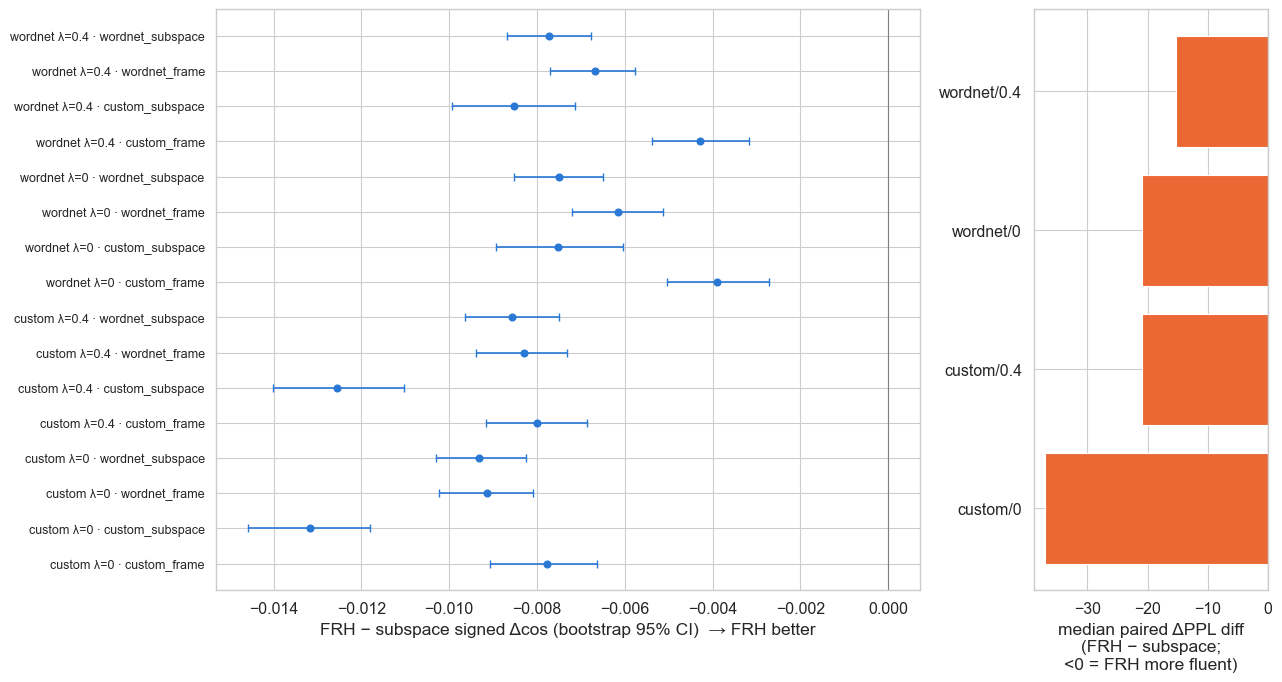

In [7]:
key = ["source", "lam", "config", "prompt", "view"]
p = cos[cos.cos_valid].pivot_table(index=key, columns="method", values="signed").dropna()
p["diff"] = p.frh_blend - p.subspace
pp = runs[runs.ppl_valid].pivot_table(index=["source", "lam", "config", "prompt"], columns="method", values="delta_ppl").dropna()
pp["diff"] = pp.frh_blend - pp.subspace

def boot(x, n=2000, rng=np.random.default_rng(0)):
    x = np.asarray(x); b = rng.choice(x, (n, len(x))).mean(1)
    return x.mean(), *np.percentile(b, [2.5, 97.5])

tab = pd.DataFrame([(s, l, v, *boot(d["diff"]), (d["diff"] > 0).mean(), len(d))
                    for (s, l, v), d in p.reset_index().groupby(["source", "lam", "view"])],
                   columns=["source", "lam", "view", "mean", "lo", "hi", "frac_frh_better", "n"])
display(tab.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw=dict(width_ratios=[3, 1]))
ax = axes[0]
labels = [f"{r.source} λ={r.lam:g} · {r.view}" for r in tab.itertuples()]
ax.errorbar(tab["mean"], range(len(tab)), xerr=[tab["mean"] - tab.lo, tab.hi - tab["mean"]], fmt="o", color="#2a78d6", capsize=3)
ax.set_yticks(range(len(tab))); ax.set_yticklabels(labels, fontsize=9); ax.axvline(0, color="0.5", lw=.8)
ax.set_xlabel("FRH − subspace signed Δcos (bootstrap 95% CI)  → FRH better")
ax = axes[1]
pt = pd.DataFrame([(f"{s}/{l:g}", d["diff"].median()) for (s, l), d in pp.reset_index().groupby(["source", "lam"])], columns=["g", "med"])
ax.barh(pt.g, pt.med, color="#eb6834"); ax.axvline(0, color="0.5", lw=.8)
ax.set_xlabel("median paired ΔPPL diff\n(FRH − subspace;\n<0 = FRH more fluent)")
fig.tight_layout(); plt.show()

## 5. Per-run distributions (own view)

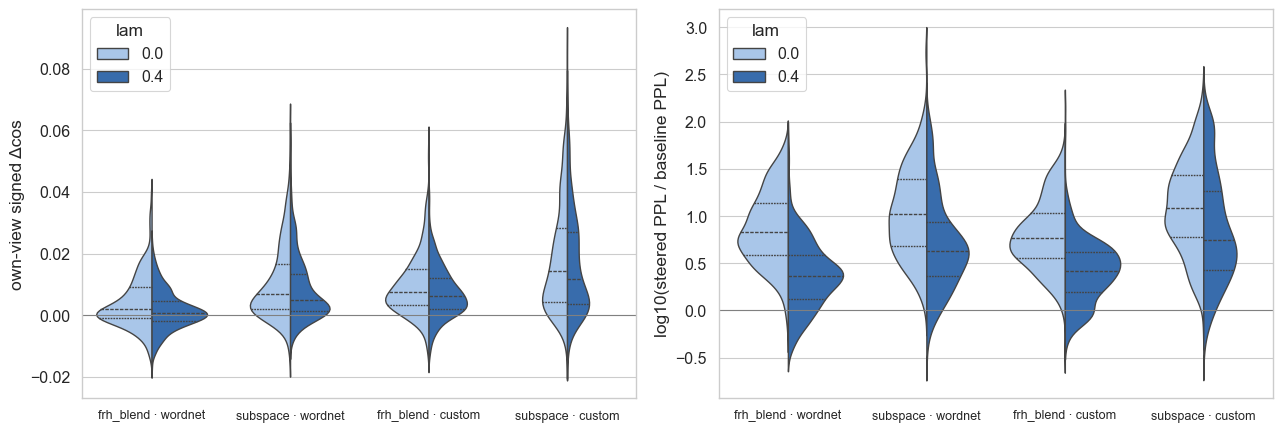

In [8]:
v = own[own.cos_valid & own.ppl_valid].copy()
v["log_ratio"] = np.log10(v.steered_ppl / v.baseline_ppl)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
v["grp"] = v.method + " · " + v.source
sns.violinplot(data=v, x="grp", y="signed", hue="lam", split=True, inner="quart", ax=axes[0], palette=["#9ec5f4", "#256abf"])
axes[0].axhline(0, color="0.5", lw=.8); axes[0].set_xlabel(""); axes[0].set_ylabel("own-view signed Δcos")
sns.violinplot(data=v, x="grp", y="log_ratio", hue="lam", split=True, inner="quart", ax=axes[1], palette=["#9ec5f4", "#256abf"])
axes[1].axhline(0, color="0.5", lw=.8); axes[1].set_xlabel(""); axes[1].set_ylabel("log10(steered PPL / baseline PPL)")
for a in axes: a.tick_params(axis="x", labelsize=9)
fig.tight_layout(); plt.show()

## 6. Per-target-concept gain (single-concept runs, own view, λ=0.4)

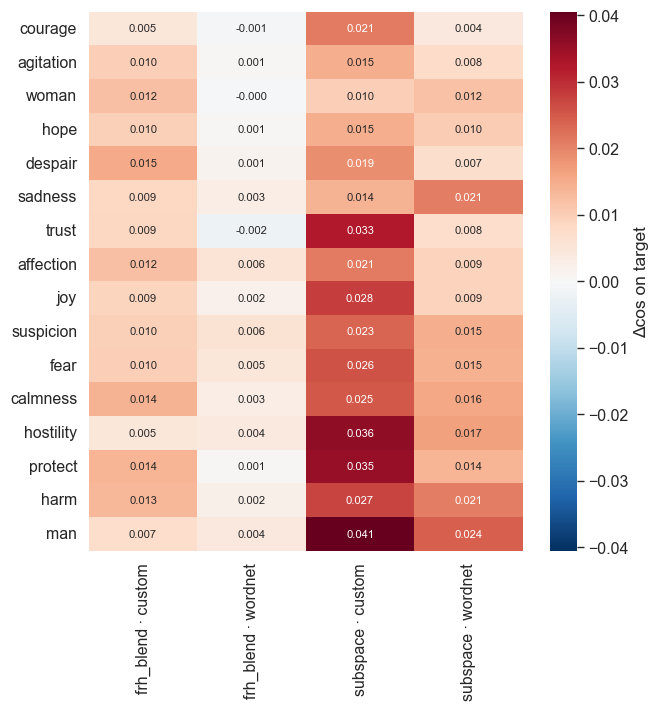

In [9]:
rows = []
for r in raw:
    if r["config"]["kind"] != "single" or r["lambda"] != 0.4: continue
    v = f'{r["source"]}_{"frame" if r["method"] == "frh_blend" else "subspace"}'
    m = r["metrics"]["cosine"][v]
    if not m["valid"]: continue
    t = r["config"]["positive"][0]
    rows.append(dict(target=t, grp=f'{r["method"]} · {r["source"]}', delta=m["per_concept"][t]["delta"]))
h = pd.DataFrame(rows).pivot_table(index="target", columns="grp", values="delta")
h = h.loc[h.mean(1).sort_values().index]
lim = np.nanmax(np.abs(h.values))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(h, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, annot=True, fmt=".3f", annot_kws=dict(size=8), ax=ax, cbar_kws=dict(label="Δcos on target"))
ax.set_xlabel(""); ax.set_ylabel(""); plt.show()

## 7. Invalid rows

All invalid rows come from prompt **p07** ("Continue this thought." / "Here is what happened next:"): its unsteered baseline is
empty (0 tokens), so neither cosine delta nor ΔPPL can be scored for any p07 run, even when the steered continuation is non-empty.

In [10]:
full = pd.DataFrame([dict(prompt=r["prompt"]["id"], method=r["method"], source=r["source"], lam=r["lambda"], ppl_valid=r["metrics"]["fluency"]["valid"], tokens=r["metrics"]["continuation_tokens"]) for r in all_raw])
inv = full.assign(is_empty=full.tokens == 0)
print("baseline tokens per prompt:", {r["prompt"]["id"]: r["metrics"]["baseline_tokens"] for r in all_raw})
display(pd.crosstab(inv.prompt, [inv.ppl_valid, inv.is_empty]))
display(inv[inv.prompt == "p07"].groupby(["method", "source", "lam"]).is_empty.mean().unstack().round(3).rename_axis(columns="λ: frac steered empty"))

baseline tokens per prompt: {'p01': 25, 'p02': 25, 'p03': 25, 'p04': 25, 'p05': 25, 'p06': 25, 'p07': 0, 'p08': 18}


ppl_valid False       True 
is_empty  False True  False
prompt                     
p01           0     0   592
p02           0     0   592
p03           0     0   592
p04           0     0   592
p05           0     0   592
p06           0     0   592
p07         383   209     0
p08           0     0   592

λ: frac steered empty    0.0    0.4
method    source                   
frh_blend custom       0.027  0.041
          wordnet      0.041  0.068
subspace  custom       0.703  0.703
          wordnet      0.568  0.676